In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer

from helper_functions.visualizations import *

data = pd.read_csv("../../preliminar_phase_submision/training_data/SyntheticData_Training.csv")
dictionary = pd.read_csv("tmp_datasets/DataDictionary.csv")
target = "inhospital_mortality"

numerical_clinical = dictionary[(dictionary['Category'].str.contains('Continuous')) & ~(dictionary['Category'].str.contains('Social'))]['Feature']
categorical_features = dictionary[~(dictionary['Category'].str.contains('Social')) & (dictionary['Category'].str.contains('Categorical'))]['Feature']
df = data[categorical_features.tolist()]

# Main Imputer Class and Strategy

* Vaccination sources: ✅
['vaccmeaslessource_adm', 'vaccpneumocsource_adm', 'vaccdptsource_adm']✅
-> Fill missing with the other source data.✅
-> Fill the rest with self-reporting. ()✅

* ['spo2onoxy_adm', 'oxygenavail_adm', 'respdistress_adm'] ✅
-> use iterativeimputer to fill these values.✅

* ['bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm', 'symptoms_adm___14', 'feedingstatus_adm']✅
-> use iterativeimputer✅

* ['deliveryloc_adm', 'birthattend_adm']✅
-> use iterativeimputer✅

* ['hctpretransfusion_adm', 'hivstatus_adm', 'malariastatuspos_adm'] ✅
-> use iterativeimputer✅

Default values✅

* 1 ['vaccpneumoc_adm', 'vaccmeasles_adm', 'vaccdpt_adm']: ✅
-> Missing values are "unknown" ✅
priorweekantimal_adm -> No ✅
priorhosp_adm -> Dont know ✅
prioryearwheeze_adm -> Dont know ✅


exclbreastfed_adm -> Unknown ✅
Currently exclusively breastfed -> use the age of the child to replace these values.✅

totalbreastfed_adm -> Unknown✅
Still being breastfed ->  use the age of the child to replace these values✅


nonexclbreastfed_adm -> new column "N/A - Exclusive" ✅
transform anything without "other" to "Formula+" ✅
anything with "other" to "Other+"✅


In [2]:
import numpy as np
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import OrdinalEncoder

class IterativeImputerClassifier:
    def __init__(self):
        # Initialize IterativeImputer with default configuration
        self.ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan)
        self.categorical_cols = ['hivstatus_adm', 'malariastatuspos_adm', 'hctpretransfusion_adm', 
                                 'spo2onoxy_adm', 'oxygenavail_adm', 'respdistress_adm', 
                                 'bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm', 'symptoms_adm___14', 
                                 'feedingstatus_adm', 'deliveryloc_adm', 'birthattend_adm', 
                                 'caprefill_adm', 'hr_bpm_adm', 'weight_kg_adm', 
                                 'vaccmeaslessource_adm', 'vaccpneumocsource_adm', 'vaccdptsource_adm', 
                                 'vaccmeasles_adm', 'vaccpneumoc_adm', 'vaccdpt_adm', 
                                 'momhiv_adm']
        self.imputer_group_A = IterativeImputer(max_iter=5, random_state=42)
        self.features_group_A = ['hivstatus_adm', 'lactate_mmolpl_adm', 'momhiv_adm']
        self.imputer_group_B = IterativeImputer(max_iter=5, random_state=42)
        self.features_group_B = ['malariastatuspos_adm', 'hctpretransfusion_adm', 'lactate_mmolpl_adm', 'hematocrit_gpdl_adm']
        self.imputer_group_C = IterativeImputer(max_iter=5, random_state=42)
        self.features_group_C = ['spo2onoxy_adm', 'oxygenavail_adm', 'respdistress_adm']
        self.imputer_group_D = IterativeImputer(max_iter=5, random_state=42)
        self.features_group_D = ['bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm', 'symptoms_adm___14', 'feedingstatus_adm']
        self.imputer_group_E = IterativeImputer(max_iter=5, random_state=42)
        self.features_group_E = ['deliveryloc_adm', 'birthattend_adm']
        self.imputer_group_F = IterativeImputer(max_iter=5, random_state=42)
        self.features_group_F = ['caprefill_adm', 'hr_bpm_adm', 'weight_kg_adm']
        self.imputer_group_G = IterativeImputer(max_iter=5, random_state=42)
        self.features_group_G = ['vaccmeasles_adm', 'vaccpneumoc_adm', 'vaccdpt_adm']
        self.imputer_group_H = IterativeImputer(max_iter=5, random_state=42)
        self.features_group_H = ['vaccmeaslessource_adm', 'vaccpneumocsource_adm', 'vaccdptsource_adm']


        self.default_values = {}
    
    def fit(self, X_train: pd.DataFrame):
        X = X_train.copy()

        self.default_values = {
            'exclbreastfed_adm': 'Unknown',
            'totalbreastfed_adm': 'Unknown',
            'vaccmeaslessource_adm': 'Self report',
            'vaccpneumocsource_adm': 'Self report',
            'vaccdptsource_adm': 'Self report',
            'vaccpneumoc_adm': 'Unknown',
            'vaccmeasles_adm': 'Unknown',
            'vaccdpt_adm': 'Unknown',
            'priorweekantimal_adm': 'Dont know',
            'priorhosp_adm': 'Dont know',
            'prioryearwheeze_adm': 'Dont know'}
        
        # Preserve NaN values and fit the OrdinalEncoder
        X[self.categorical_cols] = X[self.categorical_cols].astype(object)
        self.ordinal_encoder.fit(X[self.categorical_cols])
        X[self.categorical_cols] = self.ordinal_encoder.transform(X[self.categorical_cols])
        
        # Fit the imputers
        self.imputer_group_A.fit(X[self.features_group_A])
        self.imputer_group_B.fit(X[self.features_group_B])
        self.imputer_group_C.fit(X[self.features_group_C])
        self.imputer_group_D.fit(X[self.features_group_D])
        self.imputer_group_E.fit(X[self.features_group_E])
        self.imputer_group_F.fit(X[self.features_group_F])
        self.imputer_group_G.fit(X[self.features_group_G])
        self.imputer_group_H.fit(X[self.features_group_H])
    
    def transform(self, X_test: pd.DataFrame) -> pd.DataFrame:
        X = X_test.copy()

        # Apply categorization for 'exclbreastfed_adm' based on 'agecalc_adm'
        X['exclbreastfed_adm'] = X[['exclbreastfed_adm', 'agecalc_adm']].apply(
            self._categorize_breastfeeding, axis=1)

        # Apply categorization for 'totalbreastfed_adm' based on 'agecalc_adm'
        X['totalbreastfed_adm'] = X[['totalbreastfed_adm', 'agecalc_adm']].apply(
            self._categorize_total_breastfeeding, axis=1)
        
        # Apply categorization for 'nonexclbreastfed_adm' based on 'exclbreastfed_adm'
        X['nonexclbreastfed_adm'] = X[['nonexclbreastfed_adm', 'exclbreastfed_adm']].apply(
            self._categorize_non_exlc_breastfeeding, axis=1)
        
        # Transform categorical columns while preserving NaNs
        X[self.categorical_cols] = X[self.categorical_cols].astype(object)
        X[self.categorical_cols] = self.ordinal_encoder.transform(X[self.categorical_cols])
        
        # Impute missing values
        X[self.features_group_A] = self.imputer_group_A.transform(X[self.features_group_A])
        X[self.features_group_B] = self.imputer_group_B.transform(X[self.features_group_B])
        X[self.features_group_C] = self.imputer_group_C.transform(X[self.features_group_C])
        X[self.features_group_D] = self.imputer_group_D.transform(X[self.features_group_D])
        X[self.features_group_E] = self.imputer_group_E.transform(X[self.features_group_E])
        X[self.features_group_F] = self.imputer_group_F.transform(X[self.features_group_F])
        X[self.features_group_G] = self.imputer_group_G.transform(X[self.features_group_G])
        X[self.features_group_H] = self.imputer_group_H.transform(X[self.features_group_H])
        
        # Inverse transform categorical columns
        X[self.categorical_cols] = self.ordinal_encoder.inverse_transform(X[self.categorical_cols])

        # fill default values
        X.fillna(self.default_values, inplace=True)
        
        return X
    
    def _categorize_breastfeeding(self, row):
        if row['exclbreastfed_adm'] == "Currently exclusively breastfed":
            age_in_months = np.ceil(row['agecalc_adm'])
            if age_in_months <= 1:
                return "1 month"
            elif age_in_months <= 6:
                return f"{int(age_in_months)} months"
            else:
                return "More than 6 months"
        else:
            return row['exclbreastfed_adm']

    def _categorize_total_breastfeeding(self, row):
        if row['totalbreastfed_adm'] == "Still being breastfed":
            age_in_months = np.ceil(row['agecalc_adm'])
            if age_in_months <= 3:
                return "0-3 months"
            elif age_in_months <= 6:
                return "4-6 months"
            elif age_in_months <= 12:
                return "7-12 months"
            else:
                return ">12 months"
        else:
            return row['totalbreastfed_adm']
        
    def _categorize_non_exlc_breastfeeding(self, row):
        if pd.isna(row['nonexclbreastfed_adm']):
            if row['exclbreastfed_adm'] == "never exclusively breastfed":
                row['nonexclbreastfed_adm'] = "Mixed breastfeeding and other"
            else:
                return "N/A - exclusive breastfeeding"

        # Ensure all "Mixed breastfeeding and other" values are also transformed
        return "Other+" if "other" in str(row['nonexclbreastfed_adm']).lower() else "Formula+"


In [3]:
df_social = pd.read_csv("tmp_datasets/social_cleaned.csv").dropna(axis=1)
df_num = pd.read_csv("tmp_datasets/numerical_cleaned.csv").dropna(axis=1)
df_combined = df.combine_first(df_social)
df_combined = df_combined.combine_first(df_num)
df_combined.drop(columns=['studyid_adm', 'lengthadm'],
                  errors='ignore', inplace=True)
print(len(df_combined))

imputer = IterativeImputerClassifier()
imputer.fit(df_combined)
df_transformed = imputer.transform(df_combined)
for col in df.columns:
    missing_values = df_transformed[col].isna().sum()
    if missing_values:
        print(col, missing_values)

print(len(df_transformed))
df_transformed.to_csv("tmp_datasets/clinical_categorical_cleaned.csv", index=False)

2148
2148


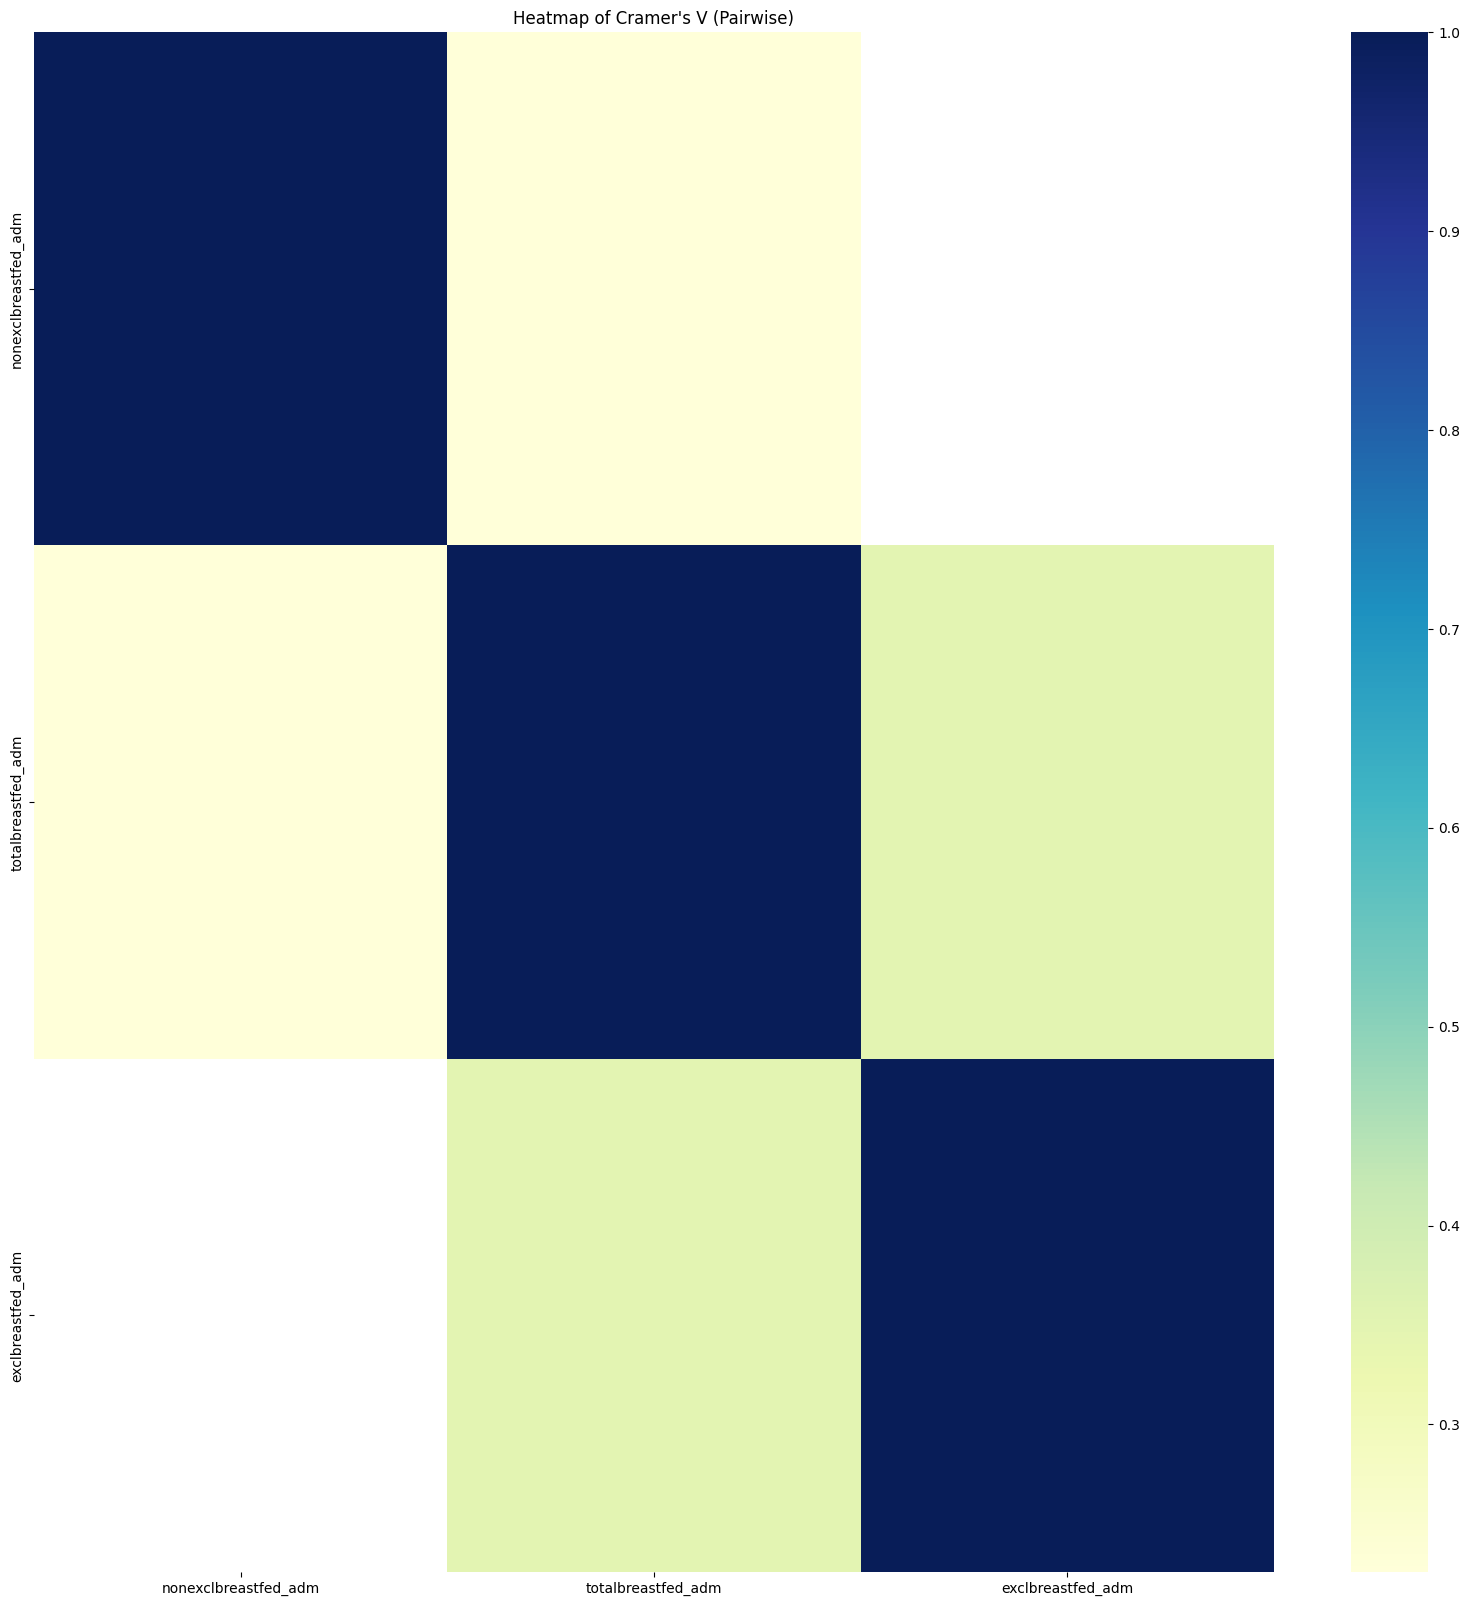

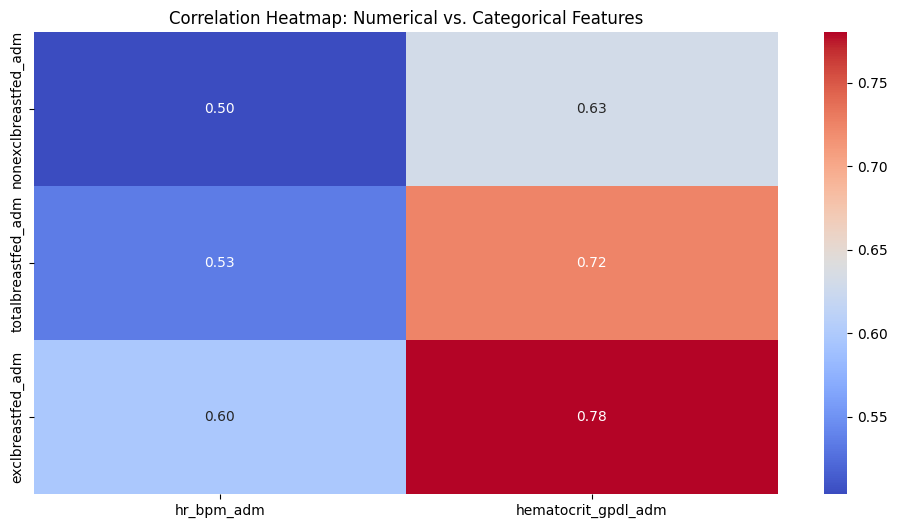

In [ ]:
heatmap_categorical_cols(df[['nonexclbreastfed_adm', 'totalbreastfed_adm', 'exclbreastfed_adm']])

heatmap_categorical_numerical_cols(df_combined[[
    'nonexclbreastfed_adm', 'totalbreastfed_adm', 'exclbreastfed_adm',
    'hr_bpm_adm', 'hematocrit_gpdl_adm']])